<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/Validacio%CC%81n_Evaluacio%CC%81n_Seleccion_274702_Sesion_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Validación_Evaluación_Seleccion
### Maestría en Inteligencia Artificial y Analítica de Datos
**Módulo:** Analítica Predictiva · Sesión 13

**Dataset:** Glioma Grading Clinical and Mutation Features

**Nombre:** Jorge Alberto Caraveo Balderas

**Matricula** 274702

---

## Contenido del Notebook

| Bloque | Tema |
|--------|------|
| 1 | Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos|
| 2 | Análisis exploratorio de datos (EDA) |
| 3 | Gráfica de Errores en Entrenamiento y Prueba |
| 4 | Optimización de hiperparámetros con RandomizedSearchCV |
| 5 | Optimización de hiperparámetros con GridSearchCV|
| 6 | Optimización de hiperparámetros con RandomizedSearchCV: Accuracy|
| 7 | Optimización de hiperparámetros con GridSearchCV: accuracy|
| 8 | Actividad de reflexión y análisis|

## Bloque 1 · Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

- 1.-Declarar las bibliotecas necesarias para este proyecto
- 2.-Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features (Se puede descargar de https://archive.ics.uci.edu/dataset/759/glioma+grading+clinical+and+mutation+features+dataset)


In [8]:
# 1 - Declarar las bibliotecas necesarias para este proyecto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score,RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score


# 2 - Cargar el conjunto de datos Glioma Grading Clinical and Mutation Features
df = pd.read_csv("TCGA_GBM_LGG_Mutations_all.csv")
print("Dimensiones:", df.shape)
display(df.head())




Dimensiones: (862, 27)


,Grade,Project,Case_ID,Gender,Age_at_diagnosis,Primary_Diagnosis,Race,IDH1,TP53,ATRX,...,FUBP1,RB1,NOTCH1,BCOR,CSMD3,SMARCA4,GRIN2A,IDH2,FAT4,PDGFRA
0,LGG,TCGA-LGG,TCGA-DU-8164,Male,51 years 108 days,"Oligodendroglioma, NOS",white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
1,LGG,TCGA-LGG,TCGA-QH-A6CY,Male,38 years 261 days,Mixed glioma,white,MUTATED,NOT_MUTATED,NOT_MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
2,LGG,TCGA-LGG,TCGA-HW-A5KM,Male,35 years 62 days,"Astrocytoma, NOS",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED
3,LGG,TCGA-LGG,TCGA-E1-A7YE,Female,32 years 283 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,MUTATED,NOT_MUTATED
4,LGG,TCGA-LGG,TCGA-S9-A6WG,Male,31 years 187 days,"Astrocytoma, anaplastic",white,MUTATED,MUTATED,MUTATED,...,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED,NOT_MUTATED


### Conclusion - Bloque 1 Carga de Bibliotecas, Conjunto de Datos y Análisis Exploratorio de los Datos

* **Carga e integridad inicial:** El archivo CSV se cargó exitosamente, confirmando una estructura de 862 registros y 27 variables
* **Inspección preliminar:** La vista previa con `df.head()` confirma que el dataset integra información de diagnóstico, características demográficas y perfiles de mutaciones genéticas, quedando listo para comenzar su análisis exploratorio formal en el siguiente bloque


## Bloque 2 · Análisis exploratorio de datos (EDA)

1.-Describir forma y estructura (shape, describe(), info()).

2.-Mostrar la distribución de clases (y.value_counts()).

3.-Visualizar:

* Histograma de al menos 3 variables numéricas.
* Boxplots o violin plots por clase si es computacionalmente viable.
* Mapa de calor de correlaciones entre variables.

4.-Concluye:
- ¿Existen clases desbalanceadas?
- ¿Qué atributos parecen más informativos?

In [9]:
# 1.- Describir forma y estructura (shape, describe(), info()).
print("1. Forma del DataFrame (shape):")
print(df.shape)
print()

print(". Información del DataFrame (info()):")
df.info()
print()

print(". Resumen estadístico (describe()):")
print(df.describe())

1. Forma del DataFrame (shape):
(862, 27)

. Información del DataFrame (info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 862 entries, 0 to 861
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Grade              862 non-null    object
 1   Project            862 non-null    object
 2   Case_ID            862 non-null    object
 3   Gender             862 non-null    object
 4   Age_at_diagnosis   862 non-null    object
 5   Primary_Diagnosis  862 non-null    object
 6   Race               862 non-null    object
 7   IDH1               862 non-null    object
 8   TP53               862 non-null    object
 9   ATRX               862 non-null    object
 10  PTEN               862 non-null    object
 11  EGFR               862 non-null    object
 12  CIC                862 non-null    object
 13  MUC16              862 non-null    object
 14  PIK3CA             862 non-null    object
 15  NF1       

Conteo absoluto de clases (y.value_counts()):
Grade
LGG    499
GBM    363
Name: count, dtype: int64

Porcentaje de clases (%):
Grade
LGG    57.89
GBM    42.11
Name: proportion, dtype: float64


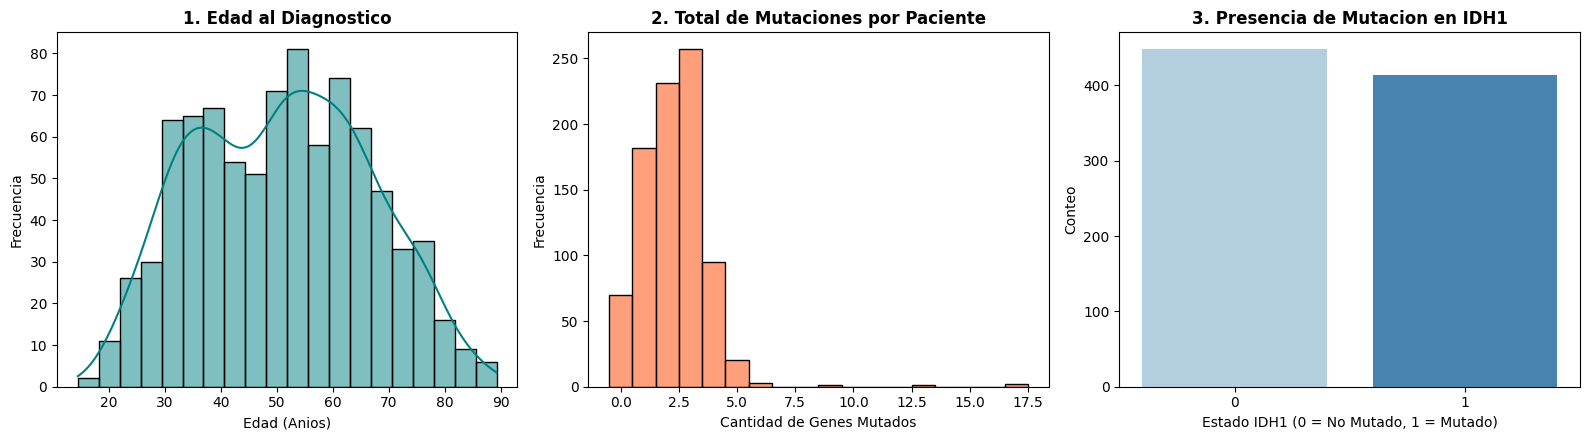

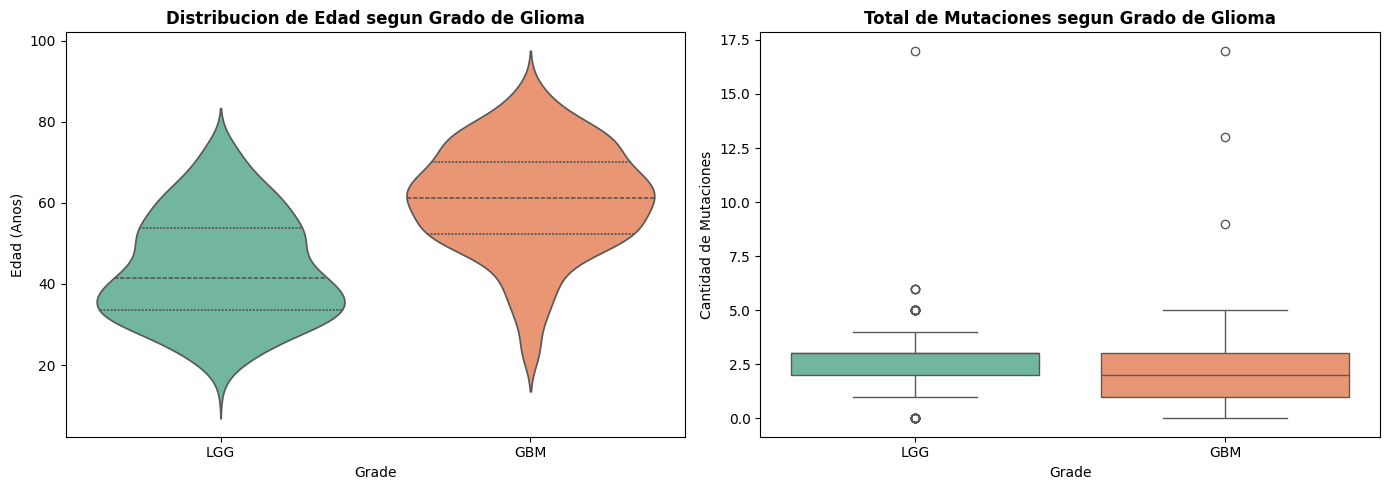

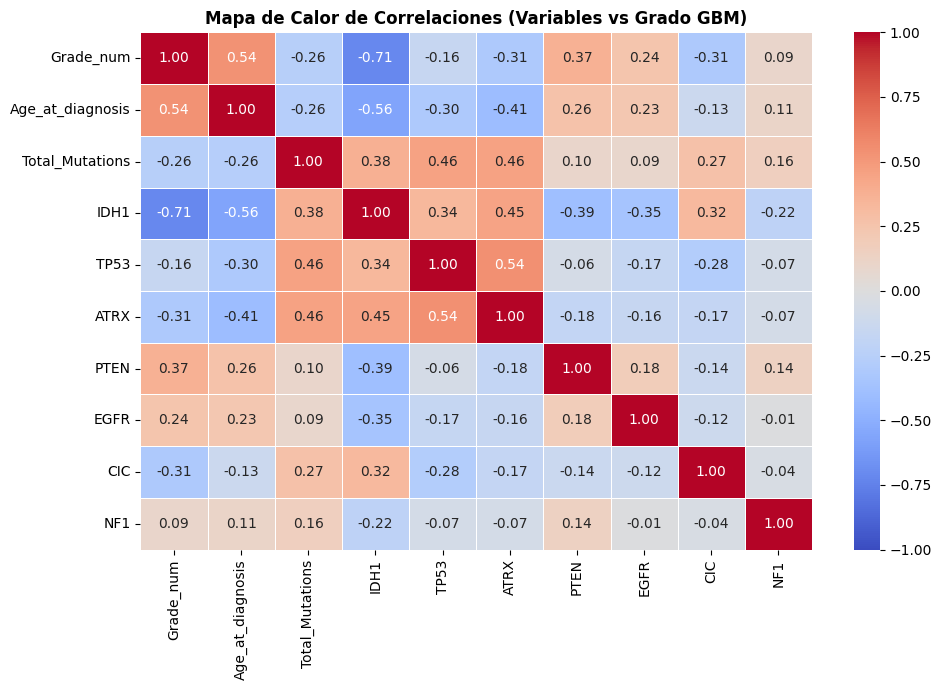

In [10]:
# 2.- Mostrar la distribución de clases (y.value_counts())
y = df['Grade']
print("Conteo absoluto de clases (y.value_counts()):")
print(y.value_counts())
print("\nPorcentaje de clases (%):")
print((y.value_counts(normalize=True) * 100).round(2))

# Conversion de la edad a formato numerico continuo debido a que en el CSV, la edad no es un número; viene guardada como "Object". Además, en el df.describe() vimos que hay pacientes con valores perdidos escritos como "--"
def convertir_edad(val):
    if pd.isna(val) or str(val).strip() in ['--', 'not reported']:
        return np.nan
    if isinstance(val, (int, float)):
        return float(val)
    try:
        partes = str(val).split()
        return round(float(partes[0]) + float(partes[2]) / 365.25, 2)
    except:
        return np.nan

df['Age_at_diagnosis'] = df['Age_at_diagnosis'].apply(convertir_edad)
df['Age_at_diagnosis'] = df['Age_at_diagnosis'].fillna(df['Age_at_diagnosis'].median()) #Se rellenan los valores "--" con la mediana de todas las edades de los pacientes

# Codificar mutaciones a 1 (MUTATED) y 0 (NOT_MUTATED) # Convertir la presencia de mutación en formato binario: 1 si está mutado, 0 si es normal para poder calcular la matriz de correlacion
columnas_no_genes = ['Grade', 'Project', 'Case_ID', 'Gender', 'Age_at_diagnosis', 'Primary_Diagnosis', 'Race', 'Total_Mutations', 'Grade_num']
genes = [col for col in df.columns if col not in columnas_no_genes]

for g in genes:
    if df[g].dtype == 'object':
        df[g] = (df[g] == 'MUTATED').astype(int)

df['Total_Mutations'] = df[genes].sum(axis=1)

# # 3 - Visualizar diferentes graficas

# Histograma de al menos 3 variables numericas
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df['Age_at_diagnosis'], kde=True, ax=axes[0], color='teal', bins=20)
axes[0].set_title('1. Edad al Diagnostico', fontweight='bold')
axes[0].set_xlabel('Edad (Anios)')
axes[0].set_ylabel('Frecuencia')

sns.histplot(df['Total_Mutations'], discrete=True, ax=axes[1], color='coral')
axes[1].set_title('2. Total de Mutaciones por Paciente', fontweight='bold')
axes[1].set_xlabel('Cantidad de Genes Mutados')
axes[1].set_ylabel('Frecuencia')

sns.countplot(data=df, x='IDH1', hue='IDH1', palette='Blues', legend=False, ax=axes[2])
axes[2].set_title('3. Presencia de Mutacion en IDH1', fontweight='bold')
axes[2].set_xlabel('Estado IDH1 (0 = No Mutado, 1 = Mutado)')
axes[2].set_ylabel('Conteo')

plt.tight_layout()
plt.show()

# Boxplots o violin plots por clase
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=df, x='Grade', y='Age_at_diagnosis', hue='Grade', palette='Set2', inner='quartile', legend=False, ax=axes[0])
axes[0].set_title('Distribucion de Edad segun Grado de Glioma', fontweight='bold')
axes[0].set_xlabel('Grade')
axes[0].set_ylabel('Edad (Anos)')

sns.boxplot(data=df, x='Grade', y='Total_Mutations', hue='Grade', palette='Set2', legend=False, ax=axes[1])
axes[1].set_title('Total de Mutaciones segun Grado de Glioma', fontweight='bold')
axes[1].set_xlabel('Grade')
axes[1].set_ylabel('Cantidad de Mutaciones')

plt.tight_layout()
plt.show()

# Mapa de calor de correlaciones entre variables
df['Grade_num'] = (df['Grade'] == 'GBM').astype(int)

vars_corr = ['Grade_num', 'Age_at_diagnosis', 'Total_Mutations', 'IDH1', 'TP53', 'ATRX', 'PTEN', 'EGFR', 'CIC', 'NF1']
matriz_corr = df[vars_corr].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Mapa de Calor de Correlaciones (Variables vs Grado GBM)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Conclusion - Bloque 2 Análisis exploratorio de datos (EDA)

* **¿Existen clases desbalanceadas?:** No existe un desbalance severo. La variable objetivo `Grade` presenta 499 casos de `LGG` (57.89%) frente a 363 casos de `GBM` (42.11%), lo que representa una proporción aproximada de 58:42. Al estar relativamente balanceadas, no es necesario aplicar técnicas complejas de remuestreo sintético (como SMOTE), pero sí es recomendable utilizar partición estratificada (`stratify=y` y `StratifiedKFold`) para mantener la misma proporción en los conjuntos de entrenamiento y prueba.

* **¿Qué atributos parecen más informativos?:**
  * **`Age_at_diagnosis` (Correlación r = +0.54):** Como muestra el gráfico de violín, la edad separa claramente ambos grupos: los pacientes con `LGG` se concentran alrededor de los 40 años (mediana), mientras que en `GBM` los diagnósticos ocurren a edades considerablemente más avanzadas, con una mediana cercana a los 60 años.
  * **Mutaciones complementarias:** `PTEN` (r = +0.37) y `EGFR` (r = +0.24) correlacionan positivamente con mayor malignidad (`GBM`), mientras que `ATRX` y `CIC` (r = -0.31) son más frecuentes en subtipos de menor grado (`LGG`).

## Bloque 3 · Gráfica de Errores en Entrenamiento y Prueba

En este ejercicio vas a entrenar un árbol de decisión con diferentes profundidas. Asimismo, en gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10
- 1.-Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None
- 2.-Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3
- 3.-Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades
- 4.-Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7
- 5.-Muestra una gráfica para los distintos resultados  cuando se usa F1 Macro

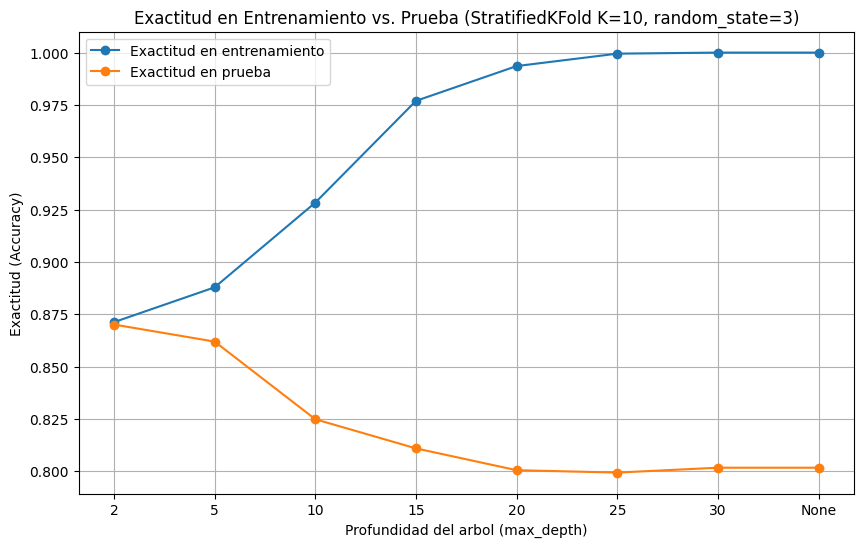

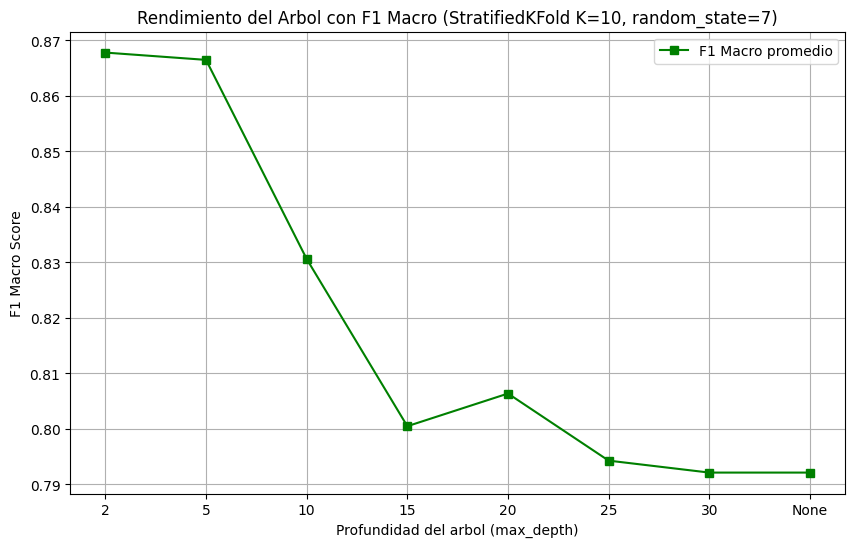

In [11]:
# Preparacion de variables predictoras (X) y objetivo (y)
cols_excluir = ['Grade', 'Project', 'Case_ID', 'Primary_Diagnosis', 'Grade_num', 'Total_Mutations']
X = df.drop(columns=[col for col in cols_excluir if col in df.columns])

# Codificar a numerico las variables categoricas restantes (Gender y Race)
le = LabelEncoder()
if 'Gender' in X.columns and X['Gender'].dtype == 'object':
    X['Gender'] = le.fit_transform(X['Gender'].astype(str))
if 'Race' in X.columns and X['Race'].dtype == 'object':
    X['Race'] = le.fit_transform(X['Race'].astype(str))

y = df['Grade']

# Los valores de las profundides a evaluar son 2, 5, 10, 15, 20, 25, 30 y None), Deberás usar StratifiedKFold con 10 particiones, y un valor aleaotorio de 3, Entrenarás y evaluarás un árbol de decisión con estos distintos valores de profundidades
profundidades = [2, 5, 10, 15, 20, 25, 30, None]
etiquetas = [str(d) for d in profundidades]

skf_3 = StratifiedKFold(n_splits=10, shuffle=True, random_state=3)

train_accuracies = []
test_accuracies = []

for depth in profundidades:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tr_scores = []
    te_scores = []

    for train_idx, test_idx in skf_3.split(X, y):
        X_train_f, X_test_f = X.iloc[train_idx], X.iloc[test_idx]
        y_train_f, y_test_f = y.iloc[train_idx], y.iloc[test_idx]

        clf.fit(X_train_f, y_train_f)
        tr_scores.append(accuracy_score(y_train_f, clf.predict(X_train_f)))
        te_scores.append(accuracy_score(y_test_f, clf.predict(X_test_f)))

    train_accuracies.append(np.mean(tr_scores))
    test_accuracies.append(np.mean(te_scores))

#  Gráfica mostrarás las exactitudes en entrenamiento y test, usando un stratified k-fold cross-validation con K= 10
plt.figure(figsize=(10, 6))
plt.plot(etiquetas, train_accuracies, label='Exactitud en entrenamiento', marker='o')
plt.plot(etiquetas, test_accuracies, label='Exactitud en prueba', marker='o')
plt.title('Exactitud en Entrenamiento vs. Prueba (StratifiedKFold K=10, random_state=3)')
plt.xlabel('Profundidad del arbol (max_depth)')
plt.ylabel('Exactitud (Accuracy)')
plt.legend()
plt.grid(True)
plt.show()

# Usa cross_val_score para entrenar los modelos, usando como métrica de evaluación en scoring ="f1_macro",y el StratifiedKFold, con un valor aleatorio = 7
skf_7 = StratifiedKFold(n_splits=10, shuffle=True, random_state=7)
f1_macro_scores = []

for depth in profundidades:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(clf, X, y, cv=skf_7, scoring='f1_macro')
    f1_macro_scores.append(scores.mean())

# Muestra una gráfica para los distintos resultados cuando se usa F1 Macro
plt.figure(figsize=(10, 6))
plt.plot(etiquetas, f1_macro_scores, label='F1 Macro promedio', marker='s', color='green')
plt.title('Rendimiento del Arbol con F1 Macro (StratifiedKFold K=10, random_state=7)')
plt.xlabel('Profundidad del arbol (max_depth)')
plt.ylabel('F1 Macro Score')
plt.legend()
plt.grid(True)
plt.show()

### Conclusion - Bloque 3 Gráfica de Errores en Entrenamiento y Prueba

* **Evidencia clara de Overfitting:** A medida que aumenta la profundidad del árbol (`max_depth > 5`), la exactitud en entrenamiento se incrementa rápidamente hasta alcanzar el 1.0 a partir de profundidad 25 y en `None`. Sin embargo, la exactitud en prueba desciende hasta alrededor del 80.0%. Esta amplia brecha entre ambas curvas demuestra que un árbol sin restricción memoriza el ruido de entrenamiento en lugar de aprender patrones

* **Identificación de la profundidad óptima:** Tanto la exactitud en prueba (87%) como el promedio de F1 Macro (0.86) alcanzan su punto máximo en `max_depth = 2` (con un desempeño muy similar en `max_depth = 5`). A partir de profundidad 10, la métrica F1 Macro cae de forma pronunciada hasta 0.79 en árboles profundos o sin podar

* **Criterio de selección del modelo:** Un árbol con profundidad baja (`max_depth` de 2 a 5) es la mejor elección: previene el sobreajuste, maximiza el balance entre precisión y sensibilidad (F1 Macro)

## Bloque 4 · Optimización de hiperparámetros con RandomizedSearchCV

1.- Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

2.- Usa el árbol de decisión
-StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- n_iter = 5 (combinaciones aleatorias a buscar)
- n_jobs = -1 para acelerar cómputo
- Métrica de evaluación: f1 Macro
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

In [12]:
# 1.- Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

# 2.- Usa el árbol de decisión -StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
clf = DecisionTreeClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X, y)
print("Mejores hiperparametros encontrados:", random_search.best_params_)
print("Mejor puntuacion F1 Macro (best_score):", round(random_search.best_score_, 4))

Mejores hiperparametros encontrados: {'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
Mejor puntuacion F1 Macro (best_score): 0.8398


### Conclusion - Bloque 4 Optimización de hiperparámetros con RandomizedSearchCV

* **Mejor configuración encontrada:** Tras evaluar 5 combinaciones aleatorias mediante validación cruzada estratificada (K=10), el algoritmo seleccionó la combinación `{'criterion': 'entropy', 'max_depth': 35, 'min_samples_split': 17}`, alcanzando una puntuación promedio de F1 Macro de 0.8398

* **Efecto del criterio y regularización:**
  * Aunque se permitió una profundidad alta (`max_depth: 35`), el hiperparámetro `min_samples_split: 17` funcionó como regularización clave, exigiendo al menos 17 observaciones para permitir una división y la creación de hojas específicas para evitar una memorización total

* **Eficiencia vs. Espacio de búsqueda (`n_iter = 5`):** `RandomizedSearchCV` demostró ser veloz para explorar múltiples combinaciones simultáneamente. No obstante, al restringir la búsqueda a solo 5 iteraciones y con un piso mínimo de `max_depth: 5`, la puntuación obtenida (0.8398) fue menor al óptimo encontrado en el Bloque 3 con árboles más simples (profundidades 2 a 5 con F1 (0.86), evidenciando que con pocas iteraciones aleatorias existe rapidez de cómputo y la garantía de hallar el óptimo global

## Bloque 5 · Optimización de hiperparámetros con GridSearchCV

1.- Define el espacio de búsqueda  para los siguientes hiperpárametros:
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

2.-Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- Métrica de evaluación: f1 Macro
- n_jobs = -1 para acelerar cómputo
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score

In [13]:
# 1.- Define el espacio de búsqueda para los siguientes hiperpárametros:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

# 2.- Usa el árbol de decisión -StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
clf = DecisionTreeClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X, y)
print("Mejores hiperparametros encontrados:", grid_search.best_params_)
print("Mejor puntuacion F1 Macro (best_score):", round(grid_search.best_score_, 4))

Mejores hiperparametros encontrados: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 14}
Mejor puntuacion F1 Macro (best_score): 0.8737


### Conclusion - Bloque 5 Optimización de hiperparámetros con GridSearchCV

* **Configuración óptima encontrada:** La búsqueda identificó la combinación `{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 14}`, alcanzando una puntuación promedio de F1 Macro de 0.8737, siendo el mejor rendimiento obtenido hasta el momento

* **Validación de la arquitectura óptima:**
  * A diferencia de `RandomizedSearchCV`, `GridSearchCV` demostró que la mejor capacidad predictiva reside en un árbol con profundidad moderada (`max_depth: 7`)**. Esto confirma las conclusiones del bloque 3. Los árboles poco profundos generalizan significativamente mejor

* **Comparativa `GridSearchCV` vs. `RandomizedSearchCV`:**
  * Rendimiento: `GridSearchCV` superó con a la búsqueda aleatoria (F1 de 0.8737 frente a 0.8398, una mejora de casi 3.5 puntos porcentuales)
  * **Costo computacional:** Mientras que `RandomizedSearchCV` solo probó 5 combinaciones, `GridSearchCV` evaluó de las 1,748 combinaciones posibles (17,480 ajustes en total con los 10 folds). Esta búsqueda fue viable gracias al tamaño medio del dataset (862 registros) y al uso de procesamiento en paralelo (`n_jobs = -1`), demostrando que cuando los recursos de cómputo lo permiten, la búsqueda garantiza encontrar el óptimo global dentro del espacio definido

## Bloque 6 ·  Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

1.-Define el espacio de búsqueda aleatorio para los siguientes hiperpárametros:
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1
2.-Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el -ejercicio considerando que es un conjunto de tamaño medio)
- n_iter = 5 (combinaciones aleatorias a buscar)
- n_jobs = -1 para acelerar cómputo
- Métrica de evaluación: accuracy
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score


In [14]:
# 1.- Define el espacio de búsqueda para los siguientes hiperpárametros:
param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

# 2.- Usa el árbol de decisión -StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
clf = DecisionTreeClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

random_search_acc = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_dist,
    n_iter=5,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

random_search_acc.fit(X, y)
print("Mejores hiperparametros encontrados:", random_search_acc.best_params_)
print("Mejor exactitud promedio (best_score):", round(random_search_acc.best_score_, 4))

Mejores hiperparametros encontrados: {'min_samples_split': 17, 'max_depth': 35, 'criterion': 'entropy'}
Mejor exactitud promedio (best_score): 0.8434


### Conclusion - Bloque 6 Optimización de hiperparámetros con RandomizedSearchCV: Accuracy

* **Configuración óptima encontrada:** La búsqueda aleatoria seleccionó la combinación `{'criterion': 'entropy', 'max_depth': 35, 'min_samples_split': 17}`, alcanzando una exactitud promedio (*Accuracy*) de 0.8434

* **Comportamiento de la métrica (Accuracy vs. F1 Macro):**
  * Al mantener el mismo espacio y semilla aleatoria (`random_state=42`), el algoritmo igualo los mismos hiperparámetros que en el Bloque 4.
  * La exactitud obtenida 0.8434 es más alta que el F1 Macro 0.8398

* **Efecto de la regularización y eficiencia computacional:**
  * Regularización: A pesar de seleccionar una profundidad alta (`max_depth: 35`), el corte de `min_samples_split: 17` y el criterio de entropía evitan una degradacion del modelo, manteniendo la exactitud por encima del 84%
  * **Costo computacional:** `RandomizedSearchCV` completó las 5 iteraciones en menor tiempo, confirmando su valor para obtener estimaciones rápidas de rendimiento, aunque con la limitación de no garantizar el óptimo global que sí se alcanza con métodos profundos

## Bloque 7 ·  Optimización de hiperparámetros con GridSearchCV: accuracy

1.-Define el espacio de búsqueda  para los siguientes hiperpárametros:
- Criterion = gini ,entropy
- max_depth: de 5 a 50 con incrementos de 1
- min_samples_split: de 2 a 20 con incrementos de 1

2.-Usa el árbol de decisión
- StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
- Métrica de evaluación: f1 Macro
- n_jobs = -1 para acelerar cómputo
- Imprime los mejores hiperparámetros encontrados
- Imprime el best_score


In [15]:
# 1.- Define el espacio de búsqueda para los siguientes hiperpárametros:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': list(range(5, 51)),
    'min_samples_split': list(range(2, 21))
}

# 2.- Usa el árbol de decisión -StratifiedKfold = 10 (no deberás realizar ninguna partición previa: realiza el ejercicio considerando que es un conjunto de tamaño medio)
clf = DecisionTreeClassifier(random_state=42)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

grid_search_acc = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

grid_search_acc.fit(X, y)
print("Mejores hiperparametros encontrados:", grid_search_acc.best_params_)
print("Mejor exactitud promedio (best_score):", round(grid_search_acc.best_score_, 4))

Mejores hiperparametros encontrados: {'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 14}
Mejor exactitud promedio (best_score): 0.8748


### Conclusion - Bloque 7 Optimización de hiperparámetros con GridSearchCV: Accuracy

* **Configuración óptima encontrada:** La búsqueda identificó la combinación `{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 14}`, alcanzando una exactitud promedio (*Accuracy*) de 0.8748, la más alta registrada en toda la practica

* **Consistencia absoluta entre métricas (Accuracy vs. F1 Macro):**
  * Tanto con *F1 Macro* (Bloque 5) como con *Accuracy* (Bloque 7), la búsqueda convergió exactamente en la misma arquitectura: **entropía, profundidad 7 y división mínima de 14 muestras**.

* **Comparativa `GridSearchCV` vs. `RandomizedSearchCV` (Accuracy):**
  * **Rendimiento:** `GridSearchCV` superó ampliamente a la búsqueda aleatoria del Bloque 6 (exactitud de 0.8748 frente a 0.8434, ganando más de 3.1 puntos porcentuales de precisión global)
  * **Costo computacional:** La búsqueda requirió 2 minutos de procesamiento para evaluar las 17,480 ejecuciones totales con soporte (`n_jobs = -1`)Aunque supuso un mayor tiempo de espera respecto a los pocos segundos de la búsqueda aleatoria, el costo computacional se justifica plenamente al garantizar la obtención del modelo más preciso y confiable posible para este conjunto de datos

## Bloque 8 ·  Actividad de reflexión y análisis

- 1.-¿Cuál método encontró mejores hiperparámetros?
- 2.-¿Cuál fue más costoso computacionalmente?
- 3.-¿Los resultados en f1_macro set fueron distintos en ambos métodos de optimización? ¿Por qué?
- 4.-¿Los resultados en accuracy set fueron distintos en ambos métodos de optimización? ¿Por qué?
- 5.-¿Los valores de hiperpárametros fueron iguales en Accuracy y F1 Macro ?


### Bloque 8 · Actividad de reflexión y análisis

* **1.- ¿Cuál método encontró mejores hiperparámetros?:** GridSearchCV encontró los mejores hiperparámetros: criterion entropy, max depth 7 y min samples split 14. Superó a la búsqueda aleatoria en ambas métricas, obteniendo un F1 Macro de 0.8737 frente a 0.8398, y una exactitud de 0.8748 frente a 0.8434. Además, seleccionó una profundidad más conservadora y generalizable de 7 en lugar de la profundidad de 35 elegida por la búsqueda aleatoria, reduciendo el riesgo de sobreajuste

* **2.- ¿Cuál fue más costoso computacionalmente?:** GridSearchCV fue sustancialmente más costoso. Al ser una búsqueda exhaustiva, evaluó las 1748 combinaciones posibles, lo que implicó 17480 ajustes de modelo con las 10 particiones de validación cruzada y tomó aproximadamente 2 minutos. En contraste, RandomizedSearchCV solo evaluó 5 combinaciones aleatorias, lo que representó 50 entrenamientos en total, finalizando en cuestion de segundos

* **3.- ¿Los resultados en f1 macro fueron distintos en ambos métodos de optimización? ¿Por qué?:** Sí, fueron distintos. GridSearchCV alcanzó un puntaje de 0.8737, superando por casi 3.4 puntos porcentuales a RandomizedSearchCV que obtuvo 0.8398. Esto se debe a que RandomizedSearchCV estuvo limitado a explorar únicamente 5 combinaciones al azar de entre 1748 posibles, por lo que la probabilidad de encontrar la configuración óptima era mas baja. En cambio, GridSearchCV evaluó cada una de las combinaciones posibles, garantizando encontrar el óptimo global

* **4.- ¿Los resultados en accuracy fueron distintos en ambos métodos de optimización? ¿Por qué?:** Sí, fueron distintos. GridSearchCV obtuvo una exactitud de 0.8748, frente al 0.8434 obtenido por RandomizedSearchCV, logrando una mejora de 3.14 por ciento. El motivo es el mismo: la evaluación descubrió que un árbol con profundidad 7 y una división mínima de 14 muestras clasifica con mayor exactitud general, mientras que la búsqueda aleatoria se quedó con la mejor de sus 5 muestras aisladas con profundidad 35

* **5.- ¿Los valores de hiperparámetros fueron iguales en Accuracy y F1 Macro?:** Sí, fueron idénticos dentro de cada método. En GridSearchCV, tanto para F1 Macro como para Accuracy, la combinación seleccionada fue criterion entropy, max depth 7 y min samples split 14. En RandomizedSearchCV, con ambas métricas la mejor combinación fue criterion entropy, max depth 35 y min samples split 17. Esto ocurre porque el conjunto de datos tiene una distribución de clases con un desbalance moderado de 58 por ciento de casos LGG frente a 42 por ciento de GBM. Al no haber un desbalance severo, la combinación que maximiza la exactitud global coincide